In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display charts inside the notebook
%matplotlib inline

# Set visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:
# Load the retail sales dataset

df = pd.read_csv("../data/retail_sales_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
# Display the first five rows

df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [5]:
# 1. Check number of rows and columns
print("Dataset Shape:", df.shape)

# 2. Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Check data types and non-null values
print("\nDataset Information:")
df.info()

# 4. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (1000, 9)

Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price 

In [6]:
# Convert Date column into datetime format

df["Date"] = pd.to_datetime(df["Date"])

# Check updated data type

print("Date column data type:", df["Date"].dtype)

# Display first five dates

df[["Date"]].head()

Date column data type: datetime64[us]


,Date
0,2023-11-24
1,2023-02-27
2,2023-01-13
3,2023-05-21
4,2023-05-06


In [7]:
# Calculate descriptive statistics

print("MEAN:")
print(df[["Age", "Quantity", "Price per Unit", "Total Amount"]].mean())

print("\nMEDIAN:")
print(df[["Age", "Quantity", "Price per Unit", "Total Amount"]].median())

print("\nMODE:")
print(df[["Age", "Quantity", "Price per Unit", "Total Amount"]].mode().iloc[0])

print("\nSTANDARD DEVIATION:")
print(df[["Age", "Quantity", "Price per Unit", "Total Amount"]].std())

MEAN:
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

MEDIAN:
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

MODE:
Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64

STANDARD DEVIATION:
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64


In [8]:
# Calculate total sales for each month

monthly_sales = df.groupby(
    df["Date"].dt.to_period("M")
)["Total Amount"].sum()

print("MONTHLY RETAIL SALES")
print(monthly_sales)

MONTHLY RETAIL SALES
Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64


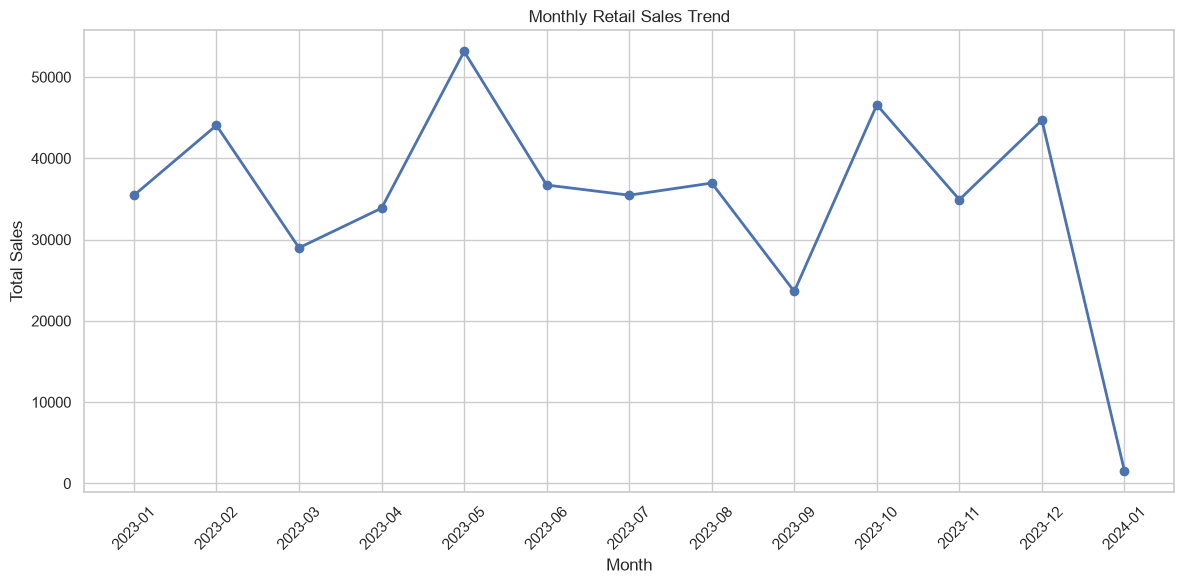

In [28]:
# Plot monthly retail sales

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig(
    "../outputs/monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [10]:
# Count transactions in each month

monthly_transactions = df.groupby(
    df["Date"].dt.to_period("M")
).size()

monthly_summary = pd.DataFrame({
    "Total Sales": monthly_sales,
    "Transactions": monthly_transactions
})

print(monthly_summary)

         Total Sales  Transactions
Date                              
2023-01        35450            76
2023-02        44060            85
2023-03        28990            73
2023-04        33870            86
2023-05        53150           105
2023-06        36715            77
2023-07        35465            72
2023-08        36960            94
2023-09        23620            65
2023-10        46580            96
2023-11        34920            78
2023-12        44690            91
2024-01         1530             2


In [11]:
# Calculate quarterly sales

quarterly_sales = df.groupby(
    df["Date"].dt.to_period("Q")
)["Total Amount"].sum()

print("QUARTERLY RETAIL SALES")
print(quarterly_sales)

QUARTERLY RETAIL SALES
Date
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64


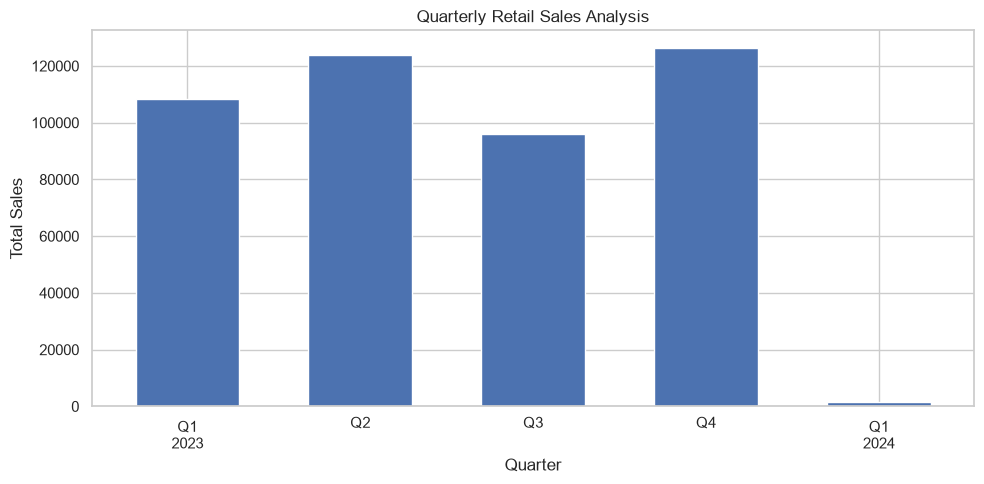

In [12]:
plt.figure(figsize=(10, 5))

quarterly_sales.plot(
    kind="bar",
    width=0.6
)

plt.title("Quarterly Retail Sales Analysis")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [13]:
# Create customer age groups

bins = [17, 25, 35, 45, 55, 65]
labels = [
    "18-25",
    "26-35",
    "36-45",
    "46-55",
    "56-65"
]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels
)

# Count customers in each age group

age_distribution = df["Age Group"].value_counts().sort_index()

print("CUSTOMER AGE DISTRIBUTION")
print(age_distribution)

CUSTOMER AGE DISTRIBUTION
Age Group
18-25    169
26-35    205
36-45    202
46-55    229
56-65    195
Name: count, dtype: int64


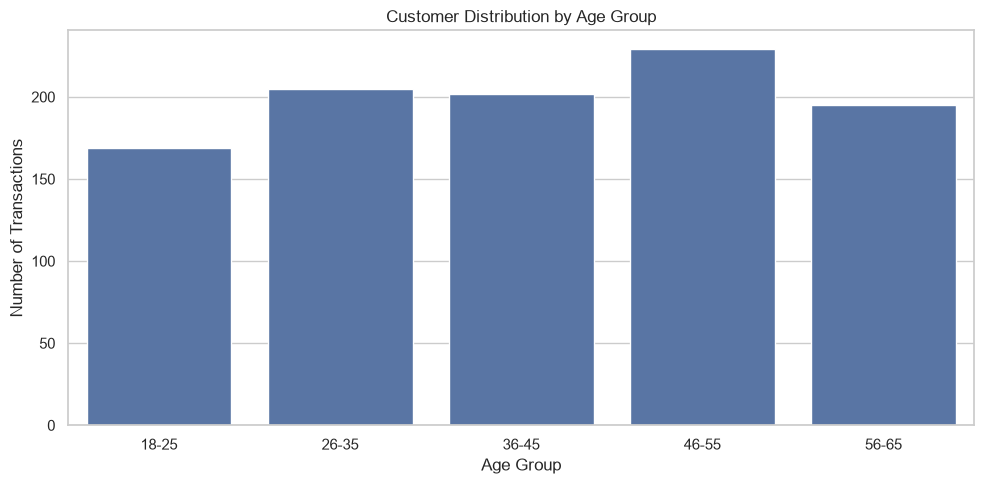

In [14]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Age Group"
)

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

In [15]:
# Analyze customer gender

gender_counts = df["Gender"].value_counts()

print("GENDER DISTRIBUTION")
print(gender_counts)

# Calculate sales by gender

gender_sales = df.groupby("Gender")["Total Amount"].sum()

print("\nTOTAL SALES BY GENDER")
print(gender_sales)

GENDER DISTRIBUTION
Gender
Female    510
Male      490
Name: count, dtype: int64

TOTAL SALES BY GENDER
Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


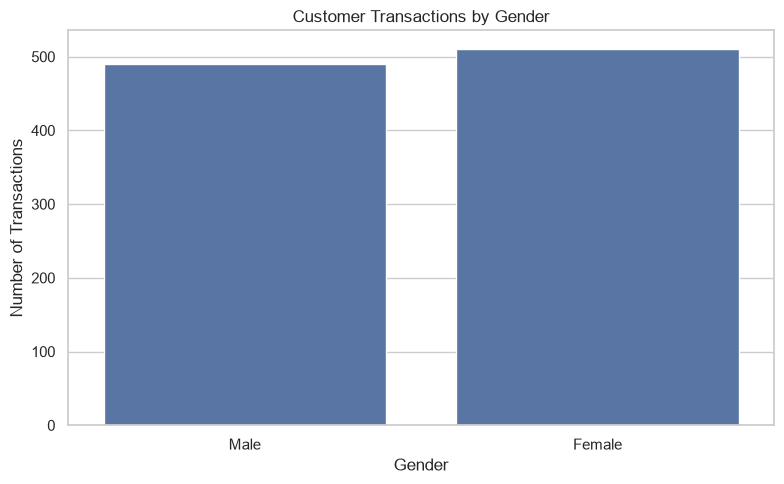

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Gender"
)

plt.title("Customer Transactions by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

In [17]:
# Analyze sales by product category

category_sales = df.groupby("Product Category")["Total Amount"].sum()

print("TOTAL SALES BY CATEGORY")
print(category_sales.sort_values(ascending=False))

TOTAL SALES BY CATEGORY
Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


In [18]:
# Count transactions in each category

category_transactions = df["Product Category"].value_counts()

print("TRANSACTIONS BY CATEGORY")
print(category_transactions)

TRANSACTIONS BY CATEGORY
Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64


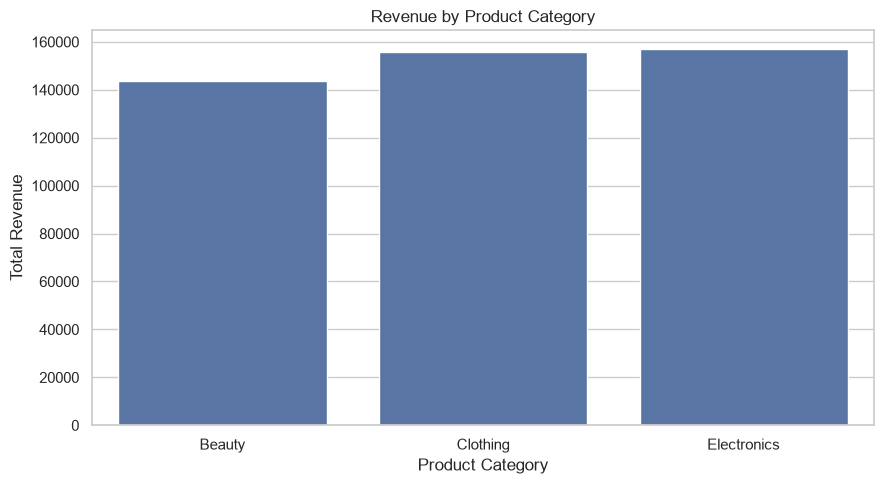

In [19]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")

plt.tight_layout()

plt.savefig("../outputs/category_revenue.png", dpi=300)

plt.show()

In [20]:
# Combine category revenue and transaction counts

category_summary = pd.DataFrame({
    "Total Revenue": category_sales,
    "Transactions": category_transactions
})

category_summary["Average Sale"] = (
    category_summary["Total Revenue"] /
    category_summary["Transactions"]
)

print(category_summary.sort_values(
    by="Total Revenue",
    ascending=False
))

                  Total Revenue  Transactions  Average Sale
Product Category                                           
Electronics              156905           342    458.786550
Clothing                 155580           351    443.247863
Beauty                   143515           307    467.475570


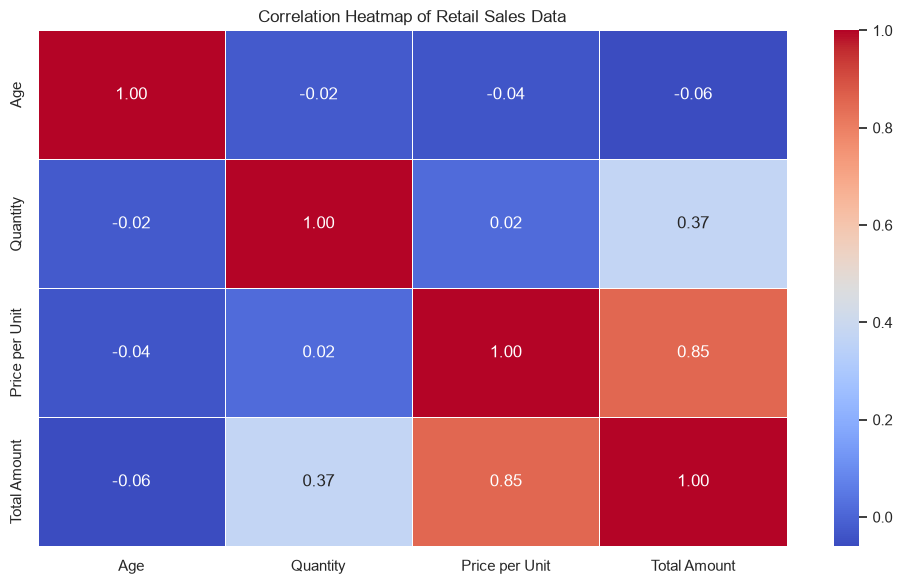

In [21]:
# Select numerical columns
# Exclude Transaction ID because it is only an identifier

numeric_df = df.select_dtypes(include="number").drop(
    columns=["Transaction ID"],
    errors="ignore"
)

# Calculate correlation
correlation_matrix = numeric_df.corr()

# Create heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Retail Sales Data")

plt.tight_layout()

plt.savefig("../outputs/correlation_heatmap.png", dpi=300)

plt.show()

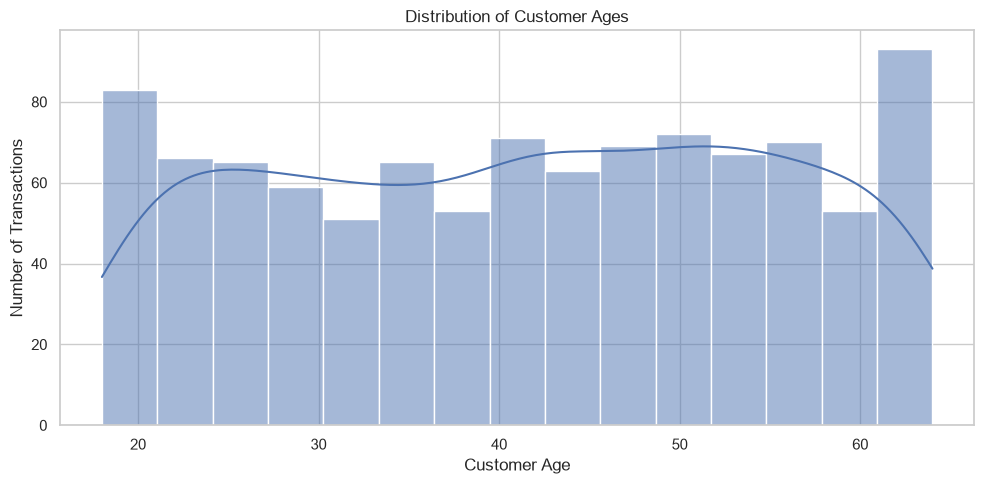

In [22]:
# Customer age distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=15,
    kde=True
)

plt.title("Distribution of Customer Ages")
plt.xlabel("Customer Age")
plt.ylabel("Number of Transactions")

plt.tight_layout()

plt.savefig("../outputs/customer_age_distribution.png", dpi=300)

plt.show()

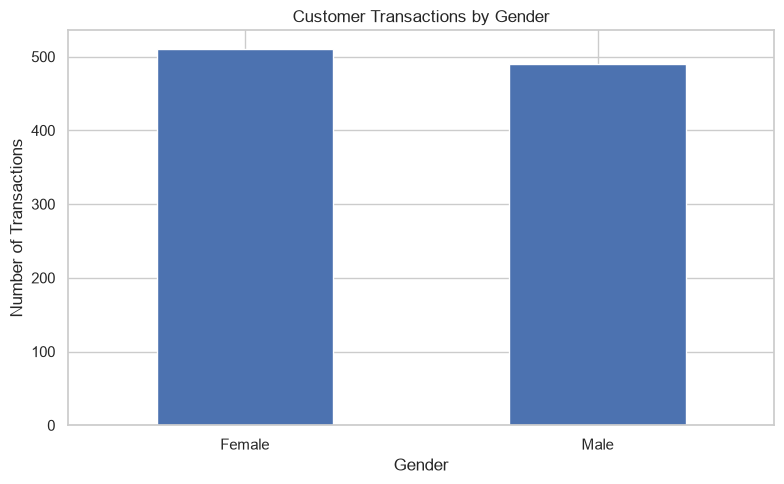

In [23]:
plt.figure(figsize=(8, 5))

gender_counts.plot(kind="bar")

plt.title("Customer Transactions by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../outputs/gender_distribution.png", dpi=300)

plt.show()

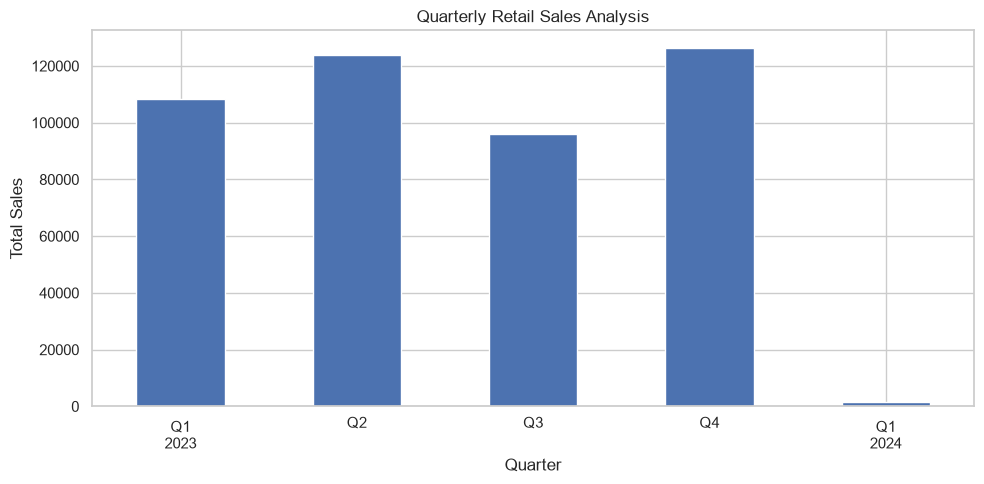

In [24]:
plt.figure(figsize=(10, 5))

quarterly_sales.plot(kind="bar")

plt.title("Quarterly Retail Sales Analysis")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../outputs/quarterly_sales.png", dpi=300)

plt.show()

In [25]:
# Create customer age groups
age_bins = [0, 20, 30, 40, 50, 60, 100]

age_labels = [
    "Below 20",
    "20-30",
    "31-40",
    "41-50",
    "51-60",
    "Above 60"
]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels
)

# Count transactions by age group
age_group_counts = df["Age Group"].value_counts().sort_index()

print("Transactions by Age Group:")
print(age_group_counts)

# Calculate revenue by age group
age_group_sales = df.groupby(
    "Age Group",
    observed=False
)["Total Amount"].sum()

print("\nRevenue by Age Group:")
print(age_group_sales)

Transactions by Age Group:
Age Group
Below 20     63
20-30       210
31-40       193
41-50       221
51-60       220
Above 60     93
Name: count, dtype: int64

Revenue by Age Group:
Age Group
Below 20     34730
20-30        98215
31-40        95950
41-50        93795
51-60       100085
Above 60     33225
Name: Total Amount, dtype: int64


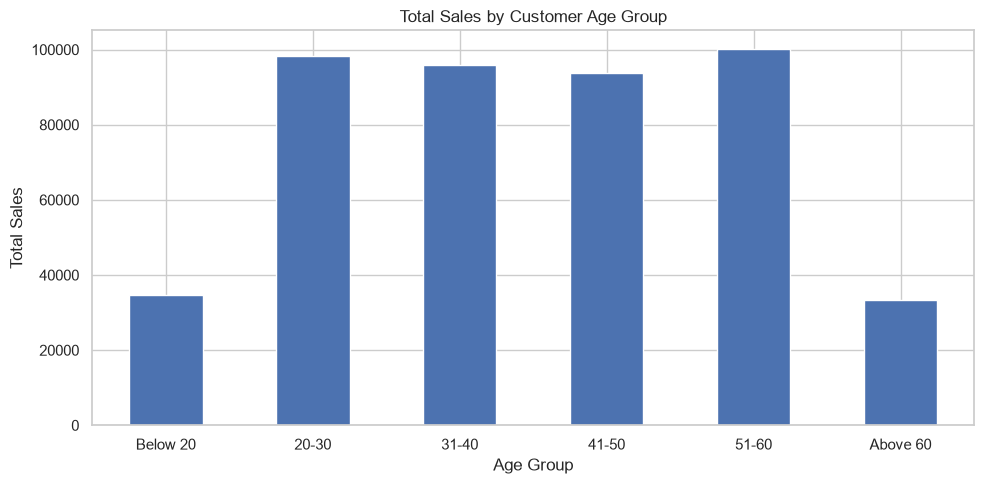

In [26]:
plt.figure(figsize=(10, 5))

age_group_sales.plot(kind="bar")

plt.title("Total Sales by Customer Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig("../outputs/age_group_sales.png", dpi=300)
plt.show()

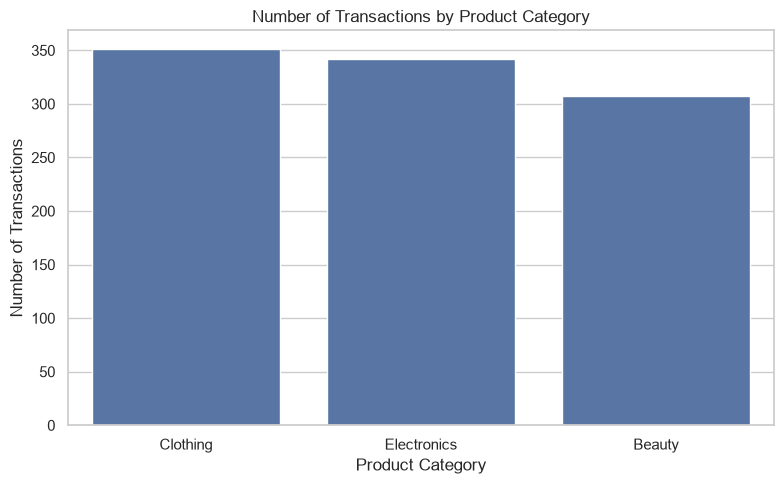

In [27]:
category_transactions = df["Product Category"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_transactions.index,
    y=category_transactions.values
)

plt.title("Number of Transactions by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.savefig("../outputs/category_transactions.png", dpi=300)
plt.show()

### Product Category Transaction Analysis – Observations

1. Clothing recorded the highest number of transactions, with 351 purchases.
2. Electronics recorded 342 transactions and generated the highest revenue of ₹156,905.
3. Beauty recorded 307 transactions but achieved the highest average sale value of approximately ₹467.48.
4. Clothing is the most frequently purchased category, while Electronics is the highest revenue-generating category.
5. The business should maintain sufficient inventory for Clothing and Electronics while exploring ways to increase Beauty product sales.

# Project Conclusion – Retail Sales Exploratory Data Analysis

This project analysed a retail sales dataset containing 1,000 transactions and 9 columns using Python, Pandas, Matplotlib and Seaborn.

The analysis covered customer demographics, product categories, monthly and quarterly sales trends, descriptive statistics and numerical correlations.

The major findings were:

1. Electronics generated the highest revenue among the three product categories.
2. Clothing recorded the highest number of transactions.
3. Customers aged 51–60 generated the highest revenue among the age groups.
4. Female customers accounted for 510 transactions, compared with 490 male transactions.
5. Monthly sales peaked in May 2023, with revenue of ₹53,150.
6. Price per Unit and Total Amount showed a strong positive correlation.

## Business Recommendations

1. **Improve inventory planning:** Maintain sufficient stock of Clothing and Electronics because they have high transaction volumes.
2. **Target customer age groups:** Develop targeted promotions for customers aged 20–60, who contribute most of the revenue.
3. **Increase Beauty category sales:** Use promotional offers and product bundles to increase transaction volume in the Beauty category.

## Data Limitations

January 2024 contains only two transactions, so the January and Q1 2024 sales figures represent incomplete periods and should not be directly compared with full months or quarters.

The dataset does not include individual product names, so the analysis focuses on product categories rather than the top 10 individual products.

## Final Summary

This project demonstrates how exploratory data analysis can help a retail business understand customer behaviour, identify sales patterns and make data-driven decisions.